# Passau MedCo · Attrition Prediction and XAI

Compare three classifiers for employee attrition, then evaluate the selected model at three decision thresholds.

## 1. Imports

Import the tools for preprocessing, training, evaluation, and plotting.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from joblib import parallel_config
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    f1_score,
    fbeta_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    train_test_split,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler

## 2. Load data

Read the employee CSV used for model training.

In [2]:
csv_path = Path("data") / "employee-attrition.csv"
employees = pd.read_csv(csv_path)
employees.columns = employees.columns.str.strip()
for column in employees.select_dtypes(include="str"):
    employees[column] = employees[column].str.strip()

## 3. Compare attrition models

Compare **logistic regression**, **random forest**, and **histogram gradient boosting**. Average precision (AP) measures ranking quality across thresholds. The [Kaggle attrition notebook](https://www.kaggle.com/code/maazbdev/emp-attrition-pred-eda-multi-model-70-recall) emphasizes recall. Here, precision at a common recall target shows how many of the flagged cases are correct when the models catch a similar share of employees who left.

### Split the data

Use a stratified 80/20 split to preserve the attrition rate. Identify constant columns on the training partition and fit each model's preprocessing inside its pipeline. The test split was inspected during project development.

In [3]:
random_seed = 42
assert not employees.duplicated().any(), "Review duplicate employee rows."
assert employees["EmployeeNumber"].notna().all() and employees["EmployeeNumber"].is_unique
assert set(employees["Attrition"]) == {"Yes", "No"}, "Review the Attrition labels."

X = employees.drop(columns=["EmployeeNumber", "Attrition"])
y = employees["Attrition"].eq("Yes").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=random_seed
)
constant_columns = X_train.columns[X_train.nunique(dropna=False).eq(1)]
X_train = X_train.drop(columns=constant_columns)
X_test = X_test.drop(columns=constant_columns)

display(pd.DataFrame({
    "Employees": [len(y_train), len(y_test)],
    "Employees who left": [y_train.sum(), y_test.sum()],
}, index=["Train", "Test"]))

,Employees,Employees who left
Train,1176,190
Test,294,47


### Set up the models and search grids

The EDA showed uneven attrition rates across job levels and stock option levels. Logistic regression uses a separate coefficient for each of these levels through one-hot encoding. The tree models can learn splits across the original level codes.

In [4]:
categorical_features = X_train.select_dtypes(include="str").columns.tolist()
numeric_features = X_train.select_dtypes(include="number").columns.tolist()
skewed_features = ["MonthlyIncome", "YearsAtCompany", "TotalWorkingYears"]
categorical_levels = ["JobLevel", "StockOptionLevel"]

linear_numeric = [
    column for column in numeric_features
    if column not in skewed_features and column not in categorical_levels
]
linear_preprocessing = ColumnTransformer([
    ("numeric", StandardScaler(), linear_numeric),
    ("skewed", StandardScaler(), skewed_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), [*categorical_features, *categorical_levels]),
])
tree_preprocessing = ColumnTransformer([
    ("numeric", "passthrough", numeric_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
])

inner_cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=random_seed)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=19)
search_options = {"cv": inner_cv, "scoring": "average_precision", "n_jobs": 4, "error_score": "raise"}

searches = {
    "Logistic regression": GridSearchCV(
        make_pipeline(linear_preprocessing, LogisticRegression(max_iter=1000)),
        {
            "logisticregression__C": [0.001, 0.01, 0.1, 1.0, 10.0],
            "logisticregression__class_weight": [None, "balanced"],
            "columntransformer__skewed": [StandardScaler(), PowerTransformer()],
        },
        **search_options,
    ),
    "Random forest": GridSearchCV(
        make_pipeline(tree_preprocessing, RandomForestClassifier(n_estimators=150, random_state=random_seed)),
        {
            "randomforestclassifier__max_depth": [8, None],
            "randomforestclassifier__min_samples_leaf": [1, 3, 8],
            "randomforestclassifier__max_features": ["sqrt", 0.6],
            "randomforestclassifier__class_weight": [None, "balanced"],
        },
        **search_options,
    ),
    "Histogram gradient boosting": GridSearchCV(
        make_pipeline(
            tree_preprocessing,
            HistGradientBoostingClassifier(
                learning_rate=0.05, l2_regularization=3.0, early_stopping=False, random_state=random_seed,
            ),
        ),
        {
            "histgradientboostingclassifier__max_leaf_nodes": [7, 15],
            "histgradientboostingclassifier__max_iter": [100, 200],
        },
        **search_options,
    ),
}

### Select the model with nested cross-validation

Each model uses the same five outer folds. Tune hyperparameters on four inner folds, then score the outer validation rows. Select the model by mean outer-fold AP. For the recall comparison, take the highest cutoff that reaches at least 70% recall in each outer fold and average its precision across folds. This describes the ranking at a common recall target.

In [5]:
out_of_fold_scores = pd.DataFrame(index=X_train.index, columns=list(searches), dtype=float)
fold_results = []
comparison_recall = 0.70

with parallel_config(backend="loky", inner_max_num_threads=1):
    for fold, (fit_indices, validation_indices) in enumerate(outer_cv.split(X_train, y_train), start=1):
        X_fit, X_validation = X_train.iloc[fit_indices], X_train.iloc[validation_indices]
        y_fit, y_validation = y_train.iloc[fit_indices], y_train.iloc[validation_indices]

        for model_name, search in searches.items():
            fitted_search = clone(search).fit(X_fit, y_fit)
            scores = fitted_search.predict_proba(X_validation)[:, 1]
            out_of_fold_scores.loc[X_validation.index, model_name] = scores

            precision, recall, _ = precision_recall_curve(y_validation, scores)
            fold_results.append({
                "Model": model_name,
                "Fold": fold,
                "AP": average_precision_score(y_validation, scores),
                "Precision at target recall": precision[recall >= comparison_recall][-1],
            })

cv_results = (
    pd.DataFrame(fold_results)
    .groupby("Model")
    .agg(**{
        "Mean CV AP": ("AP", "mean"),
        "AP fold SD": ("AP", "std"),
        "Precision at ≥70% recall": ("Precision at target recall", "mean"),
    })
    .sort_values("Mean CV AP", ascending=False)
)
display(cv_results.round(3))
selected_name = cv_results.index[0]
print(f"Selected model: {selected_name}")

,Mean CV AP,AP fold SD,Precision at ≥70% recall
Model,,,
Logistic regression,0.691,0.063,0.538
Histogram gradient boosting,0.579,0.059,0.413
Random forest,0.542,0.088,0.354


Selected model: Logistic regression


### Set decision thresholds and train the selected model

Choose the thresholds using the selected model's pooled outer-fold predictions. **F1** balances precision and recall, **F2** favors recall, and the **50% CV recall** option uses the highest cutoff that reaches at least 50% recall on those predictions. Then refit the selected model on the full training partition.

In [6]:
def choose_thresholds(labels, scores):
    precision, recall, thresholds = precision_recall_curve(labels, scores)
    precision, recall = precision[:-1], recall[:-1]
    choices = {}
    for beta in (1, 2):
        beta_squared = beta ** 2
        denominator = (beta_squared * precision + recall).clip(min=1e-12)
        f_beta = (1 + beta_squared) * precision * recall / denominator
        choices[f"F{beta}"] = float(thresholds[f_beta.argmax()])

    recall_target = 0.50
    choices[f"{recall_target:.0%} CV recall"] = float(thresholds[recall >= recall_target][-1])
    return choices

decision_thresholds = choose_thresholds(y_train, out_of_fold_scores[selected_name])
with parallel_config(backend="loky", inner_max_num_threads=1):
    final_search = clone(searches[selected_name]).fit(X_train, y_train)

selected_model = final_search.best_estimator_
decision_threshold = decision_thresholds["F1"]
print("Selected hyperparameters:")
for parameter, value in final_search.best_params_.items():
    print(f"  {parameter}: {value}")

Selected hyperparameters:
  columntransformer__skewed: PowerTransformer()
  logisticregression__C: 1.0
  logisticregression__class_weight: None


### Evaluate the selected model on the test data

Report ranking quality once, then compare precision, recall, and error counts at the three thresholds. The positive class share provides a reference AP for a constant score.

In [7]:
test_scores = selected_model.predict_proba(X_test)[:, 1]
test_predictions = test_scores >= decision_threshold
test_ap = average_precision_score(y_test, test_scores)
print(f"Test average precision: {test_ap:.3f} (constant-score reference: {y_test.mean():.3f})")

test_rows = []
for threshold_name, threshold in decision_thresholds.items():
    predictions = test_scores >= threshold
    test_rows.append({
        "Decision rule": threshold_name,
        "Cutoff": threshold,
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "F2": fbeta_score(y_test, predictions, beta=2, zero_division=0),
        "Employees who left detected": int((predictions & y_test.eq(1)).sum()),
        "False alarms": int((predictions & y_test.eq(0)).sum()),
    })

test_metrics = pd.DataFrame(test_rows).set_index("Decision rule")
display(test_metrics.round(3))

Test average precision: 0.647 (constant-score reference: 0.160)


,Cutoff,Precision,Recall,F1,F2,Employees who left detected,False alarms
Decision rule,,,,,,,
F1,0.343,0.571,0.511,0.539,0.522,24,18
F2,0.279,0.517,0.660,0.579,0.625,31,29
50% CV recall,0.466,0.719,0.489,0.582,0.523,23,9


### Visualize test errors

The confusion matrices show which employees were correctly classified at each threshold.

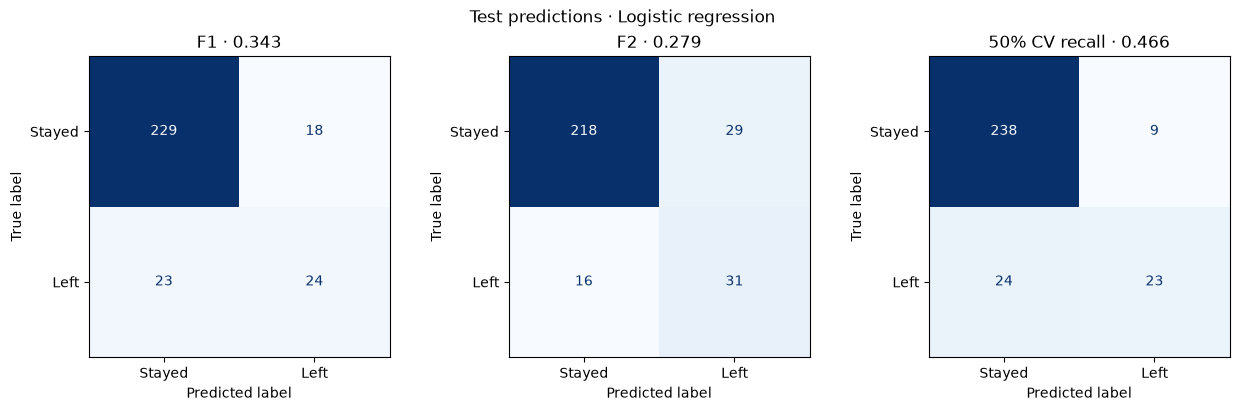

In [8]:
%matplotlib inline

fig, axes = plt.subplots(1, len(decision_thresholds), figsize=(12.6, 4), layout="constrained")
for ax, (threshold_name, threshold) in zip(axes, decision_thresholds.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, test_scores >= threshold, labels=[0, 1], display_labels=["Stayed", "Left"],
        cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(f"{threshold_name} · {threshold:.3f}")
fig.suptitle(f"Test predictions · {selected_name}")
plt.show()

### Model takeaway

- **Model choice:** Logistic regression scored highest in cross-validation (mean AP 0.691), ahead of histogram gradient boosting (0.579) and random forest (0.542). It also produced the highest precision at the common recall target (53.8%).
- **Test performance:** The selected model achieved AP 0.647. The stricter cutoff detected 23 of 47 employees who left with nine false alarms (71.9% precision). The recall-focused F2 cutoff detected 31 with 29 false alarms (66.0% recall).

## 4. Model explanations

Planned next step: explain three predictions with LIME and add a global explanation of the selected model.